In [ ]:
#import google drive and create required folder
from google.colab import drive
drive.mount('/content/drive')
#!mkdir -p /content/drive/MyDrive/pc_project/checkpoints



Mounted at /content/drive


In [ ]:
#getting code from DGCNN repo and downloading scikit-learn

%cd /content
!git clone https://github.com/WangYueFt/dgcnn.git
%cd dgcnn/pytorch
!pip install h5py scikit-learn
# checkpoints save directly to Drive
!ln -sfn /content/drive/MyDrive/pc_project/checkpoints /content/dgcnn/pytorch/checkpoints

/content
Cloning into 'dgcnn'...
remote: Enumerating objects: 187, done.
remote: Counting objects: 100% (43/43), done.
remote: Compressing objects: 100% (26/26), done.
remote: Total 187 (delta 21), reused 17 (delta 17), pack-reused 144 (from 1)
Receiving objects: 100% (187/187), 35.84 MiB | 24.85 MiB/s, done.
Resolving deltas: 100% (79/79), done.
/content/dgcnn/pytorch


In [ ]:
#Clean ModelNet40
!mkdir -p /content/dgcnn/pytorch/data
%cd /content/dgcnn/pytorch/data
!wget -q https://huggingface.co/datasets/Msun/modelnet40/resolve/main/modelnet40_ply_hdf5_2048.zip
!unzip -q modelnet40_ply_hdf5_2048.zip && rm modelnet40_ply_hdf5_2048.zip
!ls modelnet40_ply_hdf5_2048 | head
%cd /content/dgcnn/pytorch

/content/dgcnn/pytorch/data
ply_data_test0.h5
ply_data_test_0_id2file.json
ply_data_test1.h5
ply_data_test_1_id2file.json
ply_data_train0.h5
ply_data_train_0_id2file.json
ply_data_train1.h5
ply_data_train_1_id2file.json
ply_data_train2.h5
ply_data_train_2_id2file.json
/content/dgcnn/pytorch


In [ ]:
#ModelNet40-C
%cd /content
!wget -q -O modelnet40_c.zip "https://zenodo.org/records/6017834/files/modelnet40_c.zip?download=1"
!unzip -q modelnet40_c.zip && rm modelnet40_c.zip
!ls /content
%cd /content/dgcnn/pytorch

/content
dgcnn  drive  __MACOSX	modelnet40_c  sample_data
/content/dgcnn/pytorch


In [ ]:
#Getting data from Clean ModelNet40 and ModelNet40-C
import numpy as np, os
C = '/content/modelnet40_c' if os.path.exists('/content/modelnet40_c') else '/content/drive/MyDrive/pc_project/modelnet40_c'  # wherever you unzipped it
print(C)
print(sorted(os.listdir(C))[:10])
print(np.load(f'{C}/label.npy').shape, np.load(f'{C}/data_gaussian_1.npy').shape)


/content/drive/MyDrive/pc_project/modelnet40_c
['.DS_Store', 'data_background_1.npy', 'data_background_2.npy', 'data_background_3.npy', 'data_background_4.npy', 'data_background_5.npy', 'data_cutout_1.npy', 'data_cutout_2.npy', 'data_cutout_3.npy', 'data_cutout_4.npy']
(2468, 1) (2468, 1024, 3)


In [ ]:
#training the pointnet model
%cd /content/dgcnn/pytorch
!python main.py --exp_name=pointnet --model=pointnet --num_points=1024 --epochs=100

/content/dgcnn/pytorch
Namespace(exp_name='pointnet', model='pointnet', dataset='modelnet40', batch_size=32, test_batch_size=16, epochs=100, use_sgd=True, lr=0.001, momentum=0.9, no_cuda=False, seed=1, eval=False, num_points=1024, dropout=0.5, emb_dims=1024, k=20, model_path='')
Using GPU : 0 from 1 devices
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
PointNet(
  (conv1): Conv1d(3, 64, kernel_size=(1,), stride=(1,), bias=False)
  (conv2): Conv1d(64, 64, kernel_size=(1,), stride=(1,), bias=False)
  (conv3): Conv1d(64, 64, kernel_size=(1,), stride=(1,), bias=Fal

In [ ]:
#training the DGCNN model
%cd /content/dgcnn/pytorch
!python main.py --exp_name=dgcnn --model=dgcnn --num_points=1024 --k=20 --epochs=50

In [ ]:
#Loading the models + helper functions
%cd /content/dgcnn/pytorch
import torch, torch.nn as nn, torch.nn.functional as F, numpy as np
from model import PointNet, DGCNN
class A: k=20; emb_dims=1024; dropout=0.5
model = nn.DataParallel(DGCNN(A(), output_channels=40)).cuda()   # or PointNet(A(), 40)
model.load_state_dict(torch.load('checkpoints/dgcnn/models/model.t7'))
model.eval()

def predict(pts, bs=32):           # pts: (N, 1024, 3) → probabilities (N, 40)
    out = []
    with torch.no_grad():
        for i in range(0, len(pts), bs):
            x = torch.from_numpy(pts[i:i+bs]).float().cuda().permute(0, 2, 1)
            out.append(F.softmax(model(x), 1).cpu())
    return torch.cat(out).numpy()

def perturb(pts, sigma=0.01, drop=0.1):   # your small "taps"
    p = pts + np.clip(sigma*np.random.randn(*pts.shape), -2*sigma, 2*sigma)
    for b in range(len(p)):               # drop ~10% of points (replace with point 0 so N stays 1024)
        p[b, np.random.rand(p.shape[1]) < drop] = p[b, 0]
    return p.astype(np.float32)

def dropout_on(on):                       # for MC Dropout: dropout on, batchnorm stays frozen
    for m in model.modules():
        if isinstance(m, nn.Dropout): m.train(on)

/content/dgcnn/pytorch


In [ ]:
#computing the trust scores

labels = np.load(f'{C}/label.npy').flatten()

def run(file, K=8):
    pts = np.load(f'{C}/{file}').astype(np.float32)
    probs = predict(pts); pred = probs.argmax(1)
    idx = np.arange(len(pred))
    correct = (pred == labels).astype(int)
    msp = probs.max(1)
    neg_entropy = (probs * np.log(probs + 1e-12)).sum(1)       # higher = more confident

    # Proposed: K perturbed copies of the input
    pert = np.stack([predict(perturb(pts)) for _ in range(K)])  # (K, N, 40)
    ours = pert[:, idx, pred].mean(0)                            # avg prob of the original prediction (continuous) -- discrete method did not work previously
    ours_agree = (pert.argmax(2) == pred[None]).mean(0)          # fraction of copies that agree (vote count)

    # MC Dropout baseline: K passes with dropout on
    dropout_on(True)
    mc = np.stack([predict(pts) for _ in range(K)]); dropout_on(False)
    mcd = mc[:, idx, pred].mean(0)
    mcd_agree = (mc.argmax(2) == pred[None]).mean(0)

    return dict(correct=correct, msp=msp, entropy=neg_entropy,
                ours=ours, ours_agree=ours_agree, mcd=mcd, mcd_agree=mcd_agree,
                avg_pred=pert.mean(0).argmax(1))   # avg_pred is for Step 8

In [ ]:
# grading the scores
import time
from sklearn.metrics import roc_auc_score
def aurc(trust, correct):
    err = 1 - correct[np.argsort(-trust)]
    return (np.cumsum(err) / np.arange(1, len(err)+1)).mean()
def ece(conf, correct, bins=15):
    e, edges = 0, np.linspace(0, 1, bins+1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs(conf[m].mean() - correct[m].mean())
    return e

t = time.time()
r = run('data_gaussian_3.npy')
print('seconds for one file:', round(time.time() - t))
print('accuracy', r['correct'].mean())
print('avg confidence', r['msp'].mean())
for s in ['msp', 'entropy', 'mcd', 'mcd_agree', 'ours', 'ours_agree']:
    print(s, 'AUROC', roc_auc_score(r['correct'], r[s]), 'AURC', aurc(r[s], r['correct']))
print('ECE (softmax)', ece(r['msp'], r['correct']))

seconds for one file: 298
accuracy 0.8638573743922204
avg confidence 0.54194266
msp AUROC 0.8404234231215939 AURC 0.0380758183127783
entropy AUROC 0.8008897860269811 AURC 0.04729112242764246
mcd AUROC 0.8335929822210311 AURC 0.04046302123433636
mcd_agree AUROC 0.7927806441525953 AURC 0.057399931833397436
ours AUROC 0.7921943402126328 AURC 0.05328557495854437
ours_agree AUROC 0.7593815610202805 AURC 0.07139486715366054
ECE (softmax) 0.32191472269316934


In [ ]:
!nvidia-smi

Wed Nov  4 19:58:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

seconds for one file: 290
accuracy 0.8638573743922204
avg confidence 0.54194266
msp AUROC 0.8404234231215939 AURC 0.0380758183127783
entropy AUROC 0.8008897860269811 AURC 0.04729112242764246
mcd AUROC 0.8355375569552399 AURC 0.03892356652807881
mcd_agree AUROC 0.7963221991423212 AURC 0.056895495840207845
ours AUROC 0.7961979585455194 AURC 0.051386689060975155
ours_agree AUROC 0.7627304732868757 AURC 0.06993676710363204
ECE (softmax) 0.32191470915050135

In [ ]:
#Loop over all serverities 15 x 5 and save the result to Drive

import os
MODEL_NAME = 'dgcnn'      # change to 'pointnet' when you switch models
OUT = f'/content/drive/MyDrive/pc_project/results/{MODEL_NAME}'
os.makedirs(OUT, exist_ok=True)

files = sorted(f for f in os.listdir(C) if f.startswith('data_'))
files = [f for f in files if f == 'data_original.npy' or f.endswith(('_1.npy', '_3.npy', '_5.npy'))]
print(len(files), 'files')

for f in files:
    out_path = f'{OUT}/{f[:-4]}.npz'
    if os.path.exists(out_path):
        continue
    r = run(f)
    np.savez(out_path, **r)
    print(f, 'accuracy', round(r['correct'].mean(), 3))

46 files
data_upsampling_1.npy accuracy 0.876
data_upsampling_3.npy accuracy 0.858
data_upsampling_5.npy accuracy 0.718


In [1]:
#analyzing the results of both models
from google.colab import drive
drive.mount('/content/drive')
import os, glob, numpy as np, pandas as pd
from sklearn.metrics import roc_auc_score
from IPython.display import display

R = '/content/drive/MyDrive/pc_project/results'
labels = np.load('/content/drive/MyDrive/pc_project/modelnet40_c/label.npy').flatten()
for m in ['dgcnn', 'pointnet']:
    print(m, len(glob.glob(f'{R}/{m}/*.npz')), 'files')   # both should say 46

def aurc(trust, correct):
    err = 1 - correct[np.argsort(-trust)]
    return (np.cumsum(err) / np.arange(1, len(err)+1)).mean()
def ece(conf, correct, bins=15):
    e, edges = 0, np.linspace(0, 1, bins+1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs(conf[m].mean() - correct[m].mean())
    return e

methods = ['msp', 'entropy', 'mcd', 'mcd_agree', 'ours', 'ours_agree']
rows = []
for m in ['dgcnn', 'pointnet']:
    for path in sorted(glob.glob(f'{R}/{m}/*.npz')):
        d = np.load(path); name = os.path.basename(path)[5:-4]
        cor, sev = ('clean', 0) if name == 'original' else (name.rsplit('_', 1)[0], int(name.rsplit('_', 1)[1]))
        c = d['correct']
        flag = d['ours'] <= np.quantile(d['ours'], 0.2)          # 20% least-trusted predictions
        row = dict(model=m, corruption=cor, severity=sev, accuracy=c.mean(),
                   avg_confidence=d['msp'].mean(), ece_softmax=ece(d['msp'], c),
                   flagged_acc_before=c[flag].mean(),
                   flagged_acc_after=(d['avg_pred'][flag] == labels[flag]).mean(),
                   acc_with_avg_fix=(d['avg_pred'] == labels).mean())
        for s in methods:
            row[f'auroc_{s}'] = roc_auc_score(c, d[s]) if 0 < c.mean() < 1 else np.nan
            row[f'aurc_{s}'] = aurc(d[s], c)
        rows.append(row)

df = pd.DataFrame(rows)
df.to_csv(f'{R}/all_results.csv', index=False)
au = [f'auroc_{s}' for s in methods]
cor_df = df[df.severity > 0]

print('\n1) MAIN RESULT: average AUROC over all corruptions (higher = better detector)')
display(cor_df.groupby('model')[au].mean().round(3))

print('\n2) By severity: accuracy, confidence, AUROC')
display(df.groupby(['model', 'severity'])[['accuracy', 'avg_confidence'] + au].mean().round(3))

print('\n3) Best detector for each corruption')
best = cor_df.groupby(['model', 'corruption'])[['accuracy'] + au].mean().round(3)
best['best_method'] = best[au].idxmax(axis=1).str.replace('auroc_', '')
display(best)

print('\n4) Bonus fix: accuracy on the 20% least-trusted predictions, before vs after averaging')
display(cor_df.groupby(['model', 'severity'])[['accuracy', 'acc_with_avg_fix', 'flagged_acc_before', 'flagged_acc_after']].mean().round(3))

Mounted at /content/drive
dgcnn 46 files
pointnet 46 files

1) MAIN RESULT: average AUROC over all corruptions (higher = better detector)


,auroc_msp,auroc_entropy,auroc_mcd,auroc_mcd_agree,auroc_ours,auroc_ours_agree
model,,,,,,
dgcnn,0.832,0.805,0.827,0.769,0.752,0.685
pointnet,0.829,0.797,0.825,0.746,0.819,0.583



2) By severity: accuracy, confidence, AUROC


accuracy  avg_confidence  auroc_msp  auroc_entropy  \
model    severity                                                       
dgcnn    0            0.913           0.692      0.881          0.852   
         1            0.787           0.584      0.846          0.817   
         3            0.771           0.531      0.840          0.809   
         5            0.684           0.448      0.812          0.789   
pointnet 0            0.886           0.685      0.888          0.860   
         1            0.757           0.578      0.846          0.816   
         3            0.744           0.529      0.835          0.800   
         5            0.663           0.474      0.806          0.773   

                   auroc_mcd  auroc_mcd_agree  auroc_ours  auroc_ours_agree  
model    severity                                                            
dgcnn    0             0.881            0.761       0.839             0.746  
         1             0.841            0.766       0.774             0.697  
         3             0.833            0.775       0.769             0.706  
         5             0.808            0.767       0.714             0.650  
pointnet 0             0.881            0.770       0.879             0.604  
         1             0.843            0.745       0.841             0.585  
         3             0.831            0.755       0.826             0.587  
         5             0.802            0.738       0.791             0.576


3) Best detector for each corruption


accuracy  auroc_msp  auroc_entropy  auroc_mcd  \
model    corruption                                                          
dgcnn    background             0.406      0.739          0.741      0.729   
         cutout                 0.836      0.856          0.829      0.852   
         density                0.822      0.853          0.830      0.849   
         density_inc            0.866      0.863          0.832      0.856   
         distortion             0.887      0.863          0.830      0.853   
         distortion_rbf         0.877      0.856          0.822      0.851   
         distortion_rbf_inv     0.883      0.857          0.820      0.852   
         gaussian               0.845      0.837          0.799      0.829   
         impulse                0.725      0.821          0.787      0.820   
         lidar                  0.258      0.734          0.736      0.738   
         occlusion              0.402      0.772          0.762      0.770   
         rotation               0.834      0.873          0.841      0.868   
         shear                  0.892      0.868          0.834      0.862   
         uniform                0.860      0.849          0.806      0.844   
         upsampling             0.817      0.843          0.805      0.836   
pointnet background             0.114      0.585          0.575      0.575   
         cutout                 0.857      0.879          0.846      0.877   
         density                0.870      0.879          0.848      0.875   
         density_inc            0.881      0.882          0.848      0.879   
         distortion             0.796      0.851          0.817      0.845   
         distortion_rbf         0.828      0.862          0.829      0.861   
         distortion_rbf_inv     0.834      0.860          0.823      0.858   
         gaussian               0.868      0.868          0.833      0.863   
         impulse                0.765      0.845          0.814      0.841   
         lidar                  0.442      0.756          0.719      0.757   
         occlusion              0.467      0.780          0.741      0.780   
         rotation               0.645      0.799          0.770      0.794   
         shear                  0.742      0.838          0.802      0.833   
         uniform                0.855      0.878          0.846      0.874   
         upsampling             0.857      0.875          0.840      0.871   

                             auroc_mcd_agree  auroc_ours  auroc_ours_agree  \
model    corruption                                                          
dgcnn    background                    0.669       0.510             0.399   
         cutout                        0.793       0.791             0.739   
         density                       0.797       0.783             0.721   
         density_inc                   0.799       0.805             0.757   
         distortion                    0.779       0.810             0.736   
         distortion_rbf                0.793       0.808             0.745   
         distortion_rbf_inv            0.778       0.802             0.744   
         gaussian                      0.773       0.763             0.714   
         impulse                       0.781       0.658             0.589   
         lidar                         0.678       0.611             0.527   
         occlusion                     0.727       0.755             0.665   
         rotation                      0.805       0.794             0.727   
         shear                         0.789       0.827             0.760   
         uniform                       0.782       0.773             0.715   
         upsampling                    0.797       0.795             0.732   
pointnet background                    0.560       0.596             0.565   
         cutout                        0.769       0.866             0.595   
         density                       0.765      


4) Bonus fix: accuracy on the 20% least-trusted predictions, before vs after averaging


accuracy  acc_with_avg_fix  flagged_acc_before  \
model    severity                                                   
dgcnn    1            0.787             0.746               0.598   
         3            0.771             0.713               0.571   
         5            0.684             0.573               0.494   
pointnet 1            0.757             0.753               0.487   
         3            0.744             0.737               0.469   
         5            0.663             0.653               0.404   

                   flagged_acc_after  
model    severity                     
dgcnn    1                     0.443  
         3                     0.352  
         5                     0.169  
pointnet 1                     0.467  
         3                     0.436  
         5                     0.365

In [ ]:
# run ablations

In [3]:
#create figures
from google.colab import drive
drive.mount('/content/drive')
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
R = '/content/drive/MyDrive/pc_project/results'
FIG = '/content/drive/MyDrive/pc_project/figures'
os.makedirs(FIG, exist_ok=True)
df = pd.read_csv(f'{R}/all_results.csv')
cor = df[df.severity > 0]
plt.rcParams.update({'font.size': 12, 'axes.spines.top': False, 'axes.spines.right': False})
NAMES = {'dgcnn': 'DGCNN', 'pointnet': 'PointNet'}
MODEL_COL = {'dgcnn': '#2a78d6', 'pointnet': '#eb6834'}
METHODS = {'msp': ('Softmax', '#2a78d6'), 'entropy': ('Entropy', '#9aa4b2'),
           'mcd': ('MC Dropout', '#1baf7a'), 'ours': ('Ours (perturbation)', '#eb6834')}
SEV_TICKS = ([0, 1, 3, 5], ['clean', '1', '3', '5'])

Mounted at /content/drive


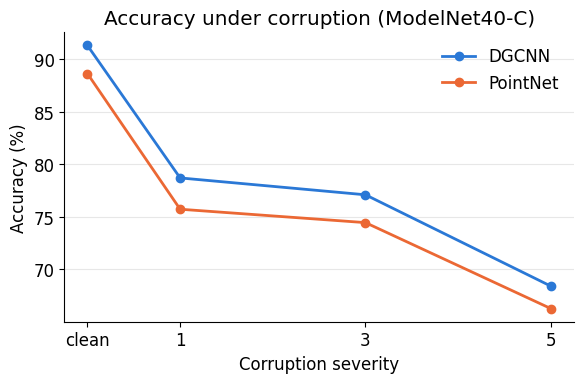

In [4]:
#Figure 1
fig, ax = plt.subplots(figsize=(6, 4))
for m, col in MODEL_COL.items():
    g = df[df.model == m].groupby('severity').accuracy.mean()
    ax.plot(g.index, g.values * 100, marker='o', lw=2, color=col, label=NAMES[m])
ax.set_xticks(*SEV_TICKS); ax.set_xlabel('Corruption severity'); ax.set_ylabel('Accuracy (%)')
ax.set_title('Accuracy under corruption (ModelNet40-C)'); ax.grid(axis='y', alpha=.3); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(f'{FIG}/1_accuracy_vs_severity.png', dpi=200); plt.show()

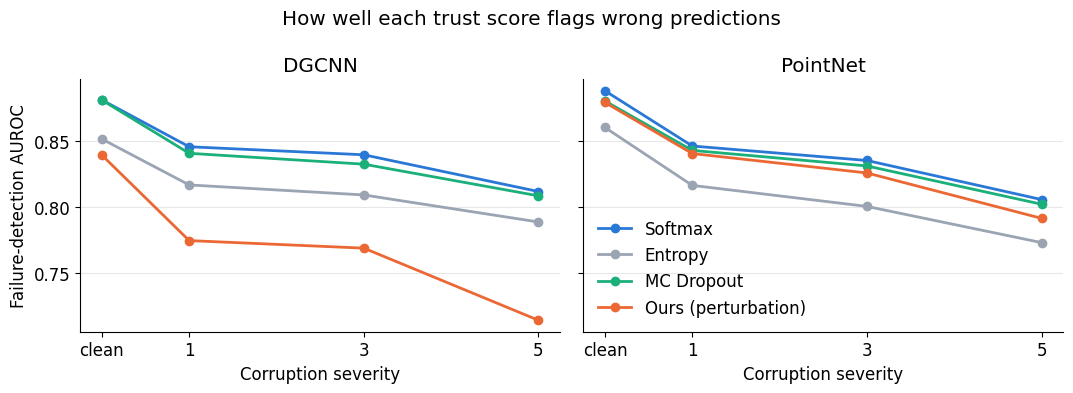

In [5]:
#Figure 2
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, m in zip(axes, ['dgcnn', 'pointnet']):
    g = df[df.model == m].groupby('severity')
    for s, (lab, col) in METHODS.items():
        v = g[f'auroc_{s}'].mean()
        ax.plot(v.index, v.values, marker='o', lw=2, color=col, label=lab)
    ax.set_title(NAMES[m]); ax.set_xticks(*SEV_TICKS); ax.set_xlabel('Corruption severity'); ax.grid(axis='y', alpha=.3)
axes[0].set_ylabel('Failure-detection AUROC'); axes[1].legend(frameon=False, loc='lower left')
fig.suptitle('How well each trust score flags wrong predictions')
fig.tight_layout(); fig.savefig(f'{FIG}/2_auroc_vs_severity.png', dpi=200); plt.show()


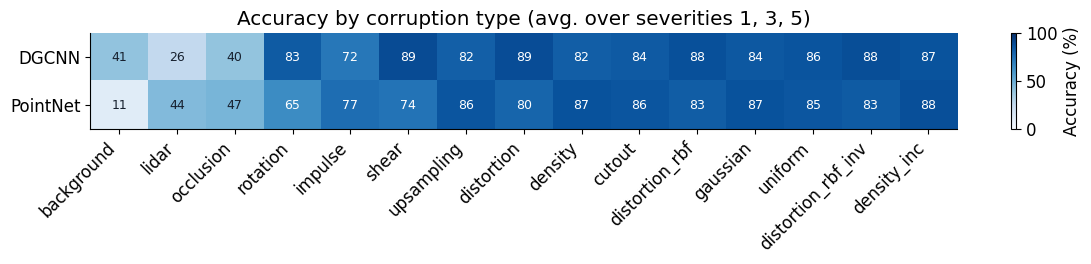

In [6]:
#Figure 3
piv = cor.pivot_table(index='model', columns='corruption', values='accuracy', aggfunc='mean')
piv = piv[piv.mean().sort_values().index]            # hardest corruption on the left
fig, ax = plt.subplots(figsize=(12, 2.8))
im = ax.imshow(piv.values * 100, cmap='Blues', vmin=0, vmax=100, aspect='auto')
ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels(piv.columns, rotation=45, ha='right')
ax.set_yticks(range(piv.shape[0])); ax.set_yticklabels([NAMES[i] for i in piv.index])
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j] * 100
        ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=9, color='white' if v > 60 else '#16202E')
fig.colorbar(im, ax=ax, label='Accuracy (%)')
ax.set_title('Accuracy by corruption type (avg. over severities 1, 3, 5)')
fig.tight_layout(); fig.savefig(f'{FIG}/3_accuracy_heatmap.png', dpi=200); plt.show()

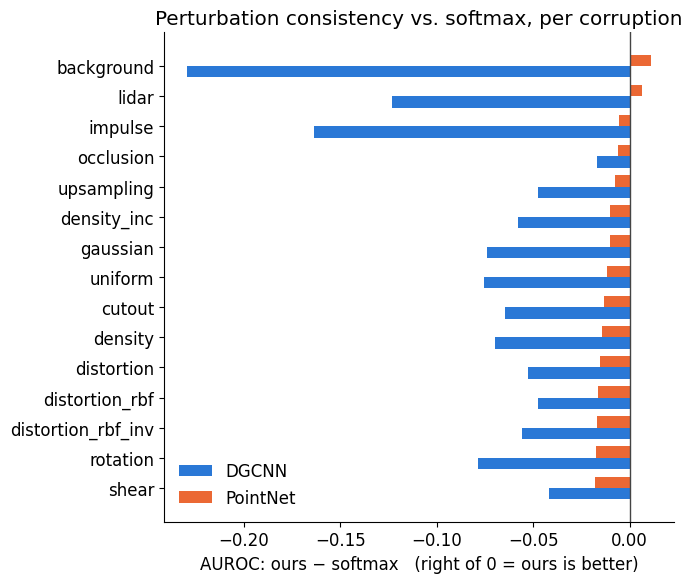

In [7]:
#Figure 4
diff = (cor.assign(d=cor.auroc_ours - cor.auroc_msp)
           .pivot_table(index='corruption', columns='model', values='d', aggfunc='mean')
           .sort_values('pointnet'))
fig, ax = plt.subplots(figsize=(7, 6)); y = np.arange(len(diff)); h = 0.38
ax.barh(y - h/2, diff['dgcnn'], h, color=MODEL_COL['dgcnn'], label='DGCNN')
ax.barh(y + h/2, diff['pointnet'], h, color=MODEL_COL['pointnet'], label='PointNet')
ax.axvline(0, color='#444', lw=1)
ax.set_yticks(y); ax.set_yticklabels(diff.index)
ax.set_xlabel('AUROC: ours − softmax   (right of 0 = ours is better)')
ax.set_title('Perturbation consistency vs. softmax, per corruption'); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(f'{FIG}/4_ours_vs_softmax.png', dpi=200); plt.show()